In [14]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator

import susi.io.load_output_data as load_output
from analysis.notebooks.components import (
    folder_selection,
    metadata_display,
    quick_look_plots,
    variable_selection,
)
from susi.io import project_layout
from susi.io.app_settings import AppSettings
from susi.io.load_output_data import (
    NetcdfAggregationFn,
    NetcdfVariableArray,
    NetcdfVariablePath,
    OutputDataStore,
    ScenarioID,
    StandID,
)
from susi.io.stand_data import load_stand_data_document_from_json

In [15]:
RUN_PATH = Path("/home/txart/projects/hiket/susi_26/projects/phase4/outputs/run_01")

# Read data


In [16]:
def simulations_table(metadata_by_stand: dict[StandID, pd.DataFrame]) -> pd.DataFrame:
    """
    One row per simulation (stand x scenario) with the columns the plots group by.
    Every table below starts from this one, so its columns are the shared vocabulary.
    """
    metadata = pd.concat(metadata_by_stand.values(), ignore_index=True)
    return pd.DataFrame(
        {
            "stand_id": metadata["stand_id"],
            "scenario_id": metadata["scenario_id"],
            "region": metadata["tags.region"],
            "site_fertility_class": metadata["stand_params.site_fertility_class"],
            "start_year": pd.to_datetime(metadata["simulation_config.start_date"]).dt.year,
        }
    )


def load_run(
    run_path: Path, variables: list[NetcdfVariablePath]
) -> tuple[OutputDataStore, pd.DataFrame]:
    """
    The only function that touches the output files: every netcdf file is opened
    once and all `variables` are read in that single pass. Opening is the slow
    part (~90 ms per file, see issue #359), so list every variable you may want
    to plot here rather than calling this again for each one.
    """
    metadata_by_stand = load_output.load_all_metadatas_from_stands(
        folders=load_output.list_stand_folders(run_dirpath=run_path)
    )
    store = load_output.read_netcdf_files_for_selected_variables_from_metadatas(
        selected_variables=variables, metadata_by_stand=metadata_by_stand
    )
    return store, simulations_table(metadata_by_stand)


def variable_labels(run_path: Path) -> dict[NetcdfVariablePath, str]:
    """
    Axis label of every netcdf variable, taken from its `units` attribute,
    which already holds a description plus units, e.g. "stand volume [m3/ha]".
    All simulations share the same netcdf structure, so one file is enough.
    """
    variable_infos = load_output.list_all_netcdf_variables(
        netcdf_filepath=load_output.netcdf_filepath_of_first_scenario(run_dirpath=run_path)
    )
    return {path: info.units for path, info in variable_infos.items()}

In [17]:
# Every variable to plot, each with how to collapse its (year x column) array
# into one value per simulation for the per-stand plots. Same shape as the
# optimization's target specs, minus the direction.
AGGREGATIONS: dict[NetcdfVariablePath, NetcdfAggregationFn] = {
    NetcdfVariablePath("/stand/volume"): NetcdfVariableArray.spatial_mean_at_last_timestep,
}
# Fixed scenario order for every x axis and legend
SCENARIOS = [ScenarioID("control"), ScenarioID("DNM_80"), ScenarioID("ash_fertilization")]

store, simulations = load_run(run_path=RUN_PATH, variables=list(AGGREGATIONS))
LABELS = variable_labels(run_path=RUN_PATH)
simulations

,stand_id,scenario_id,region,site_fertility_class,start_year
0,197690,ash_fertilization,pirkanmaa,4,2004
1,197690,DNM_80,pirkanmaa,4,2004
2,197690,control,pirkanmaa,4,2004
3,4610438,ash_fertilization,pohjanmaa,5,2004
4,4610438,DNM_80,pohjanmaa,5,2004
5,4610438,control,pohjanmaa,5,2004
6,4610535,ash_fertilization,pohjanmaa,4,2004
7,4610535,DNM_80,pohjanmaa,4,2004
8,4610535,control,pohjanmaa,4,2004
9,4610660,ash_fertilization,pohjanmaa,4,2004


# Per-stand values over time by region
Figures show:
- Subplot columns: the two regions (the "region" tag in metadata.json), sharing the Y axis
- Y axis is a variable (e.g., volume), X axis is time (years)
- One line per stand in a given scenario. Each point is the spatial mean of the variable (in case of volume: per hectare volume, not weighted by stand area)
- The legend distinguishes scenarios

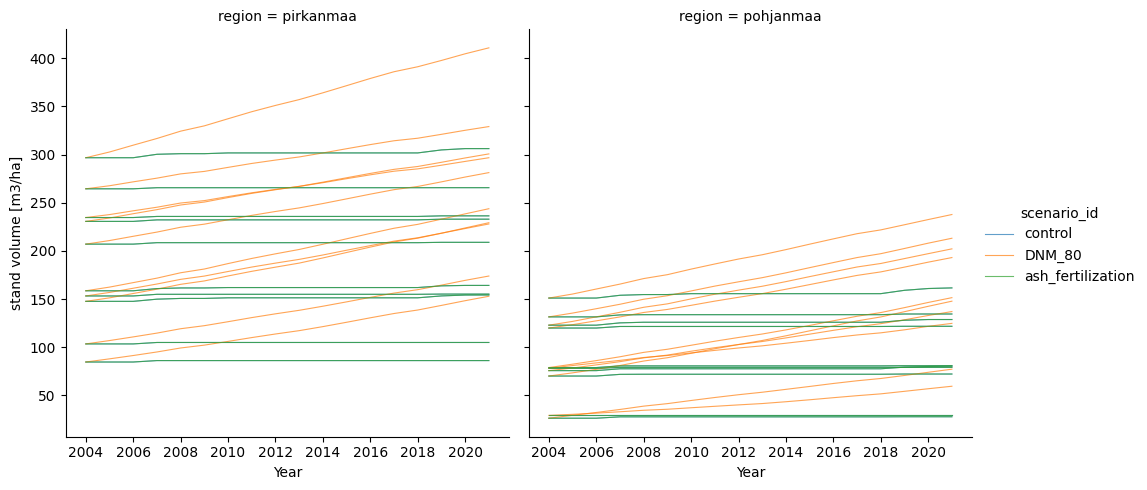

In [18]:
def timeseries_table(
    store: OutputDataStore,
    simulations: pd.DataFrame,
    variables: list[NetcdfVariablePath],
) -> pd.DataFrame:
    """
    One row per simulation and year, one column per variable holding the
    spatial mean (over the soil columns, ditches excluded) of that year.
    Row i of the netcdf is the state at the start of year start_year + i
    (row 0 is the initial state).
    """
    tables = []
    for simulation in simulations.itertuples(index=False):
        values = {
            variable: store.get_variable_value_for_scenario_and_stand(
                variable_path=variable,
                stand_id=simulation.stand_id,
                scenario_id=simulation.scenario_id,
            ).mean_over_space()
            for variable in variables
        }
        n_years = len(next(iter(values.values())))
        years = simulation.start_year + np.arange(n_years)
        # Scalar columns (stand_id, region, ...) are broadcast to every year
        tables.append(pd.DataFrame({**simulation._asdict(), "year": years, **values}))
    return pd.concat(tables, ignore_index=True)


def plot_timeseries_by_region(
    timeseries: pd.DataFrame,
    variable: NetcdfVariablePath,
    ylabel: str,
    scenario_order: list[ScenarioID],
) -> sns.FacetGrid:
    # units + estimator=None: one line per stand instead of a mean with a band
    grid = sns.relplot(
        data=timeseries,
        kind="line",
        x="year",
        y=variable,
        col="region",
        hue="scenario_id",
        hue_order=scenario_order,
        units="stand_id",
        estimator=None,
        linewidth=0.8,
        alpha=0.7,
    )
    grid.set_axis_labels("Year", ylabel)
    # Whole years only (default ticks give 2007.5)
    for ax in grid.axes.flat:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    return grid


timeseries = timeseries_table(store=store, simulations=simulations, variables=list(AGGREGATIONS))
variable = NetcdfVariablePath("/stand/volume")
plot_timeseries_by_region(
    timeseries=timeseries, variable=variable, ylabel=LABELS[variable], scenario_order=SCENARIOS
);

# Mean by scenario and region
Plot shows a comparison of the mean <variable> over stands per region and scenario (not weighted by stand area):
- Y axis is a variable (e.g., volume), X axis is discrete with one tick for each of the 3 scenarios
- Each category in the X axis has 2 barplots: one per region.

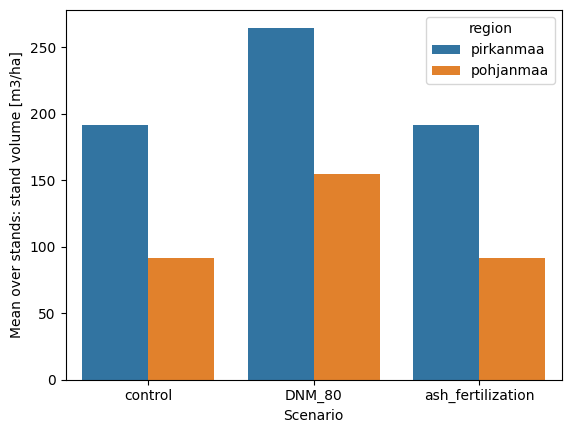

In [19]:
def stand_table(
    store: OutputDataStore,
    simulations: pd.DataFrame,
    aggregations: dict[NetcdfVariablePath, NetcdfAggregationFn],
) -> pd.DataFrame:
    """
    One row per simulation, one column per variable holding the value its
    aggregation collapses the (year x column) array into.
    """
    stands = simulations.copy()
    for variable, aggregation in aggregations.items():
        stands[variable] = [
            aggregation(
                store.get_variable_value_for_scenario_and_stand(
                    variable_path=variable, stand_id=stand_id, scenario_id=scenario_id
                )
            )
            for stand_id, scenario_id in zip(stands["stand_id"], stands["scenario_id"])
        ]
    return stands


def plot_mean_by_scenario_and_region(
    stands: pd.DataFrame,
    variable: NetcdfVariablePath,
    ylabel: str,
    scenario_order: list[ScenarioID],
) -> plt.Figure:
    fig, ax = plt.subplots()
    # barplot's default estimator is the mean; plot below shows the spread
    sns.barplot(
        data=stands,
        x="scenario_id",
        y=variable,
        hue="region",
        order=scenario_order,
        errorbar=None,
        ax=ax,
    )
    ax.set(xlabel="Scenario", ylabel=f"Mean over stands: {ylabel}")
    return fig


stands = stand_table(store=store, simulations=simulations, aggregations=AGGREGATIONS)
variable = NetcdfVariablePath("/stand/volume")
plot_mean_by_scenario_and_region(
    stands=stands, variable=variable, ylabel=LABELS[variable], scenario_order=SCENARIOS
);

# Site fertility class per region for each scenario 
Figure shows a comparison of per-stand <variable> per region and scenario:
- Y axis is a variable (e.g., volume), X axis is discrete with one tick for each of the 3 scenarios
- 2 subplots sharing the Y axis, one per region.
- Each point corresponds to a single stand.
- Legend distinguishes site fertility class of each stand

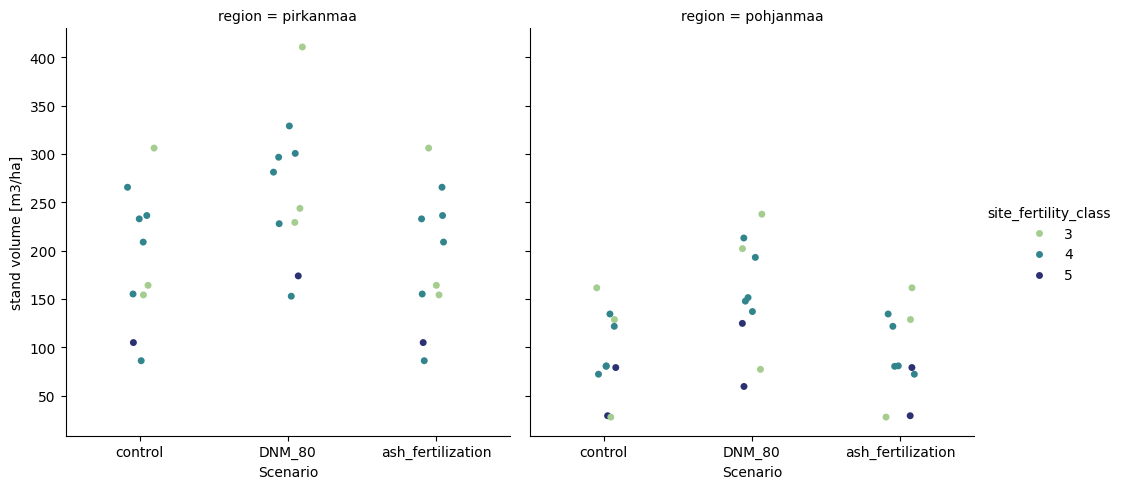

In [20]:
def plot_stand_values_by_sfc(
    stands: pd.DataFrame,
    variable: NetcdfVariablePath,
    ylabel: str,
    scenario_order: list[ScenarioID],
) -> sns.FacetGrid:
    # Site fertility class is ordinal, hence a sequential palette
    grid = sns.catplot(
        data=stands,
        kind="strip",
        x="scenario_id",
        y=variable,
        col="region",
        hue="site_fertility_class",
        order=scenario_order,
        palette="crest",
    )
    grid.set_axis_labels("Scenario", ylabel)
    return grid


variable = NetcdfVariablePath("/stand/volume")
plot_stand_values_by_sfc(
    stands=stands, variable=variable, ylabel=LABELS[variable], scenario_order=SCENARIOS
);